[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jseborga/recursos-ia/blob/main/notebooks/03_fisica_avanzada.ipynb)

# Física avanzada: cuando el método numérico importa

Cinco ejemplos en los que **elegir mal el método da resultados falsos que se ven bien**. Por eso son la mejor razón para verificar el código que escribe una IA.

| # | Ejemplo | Lección numérica | Control |
|---|---|---|---|
| 1 | Órbitas de Kepler | Integrador simpléctico frente a RK4 | Energía y tercera ley de Kepler |
| 2 | Péndulo doble | Caos y sensibilidad a condiciones iniciales | Conservación de la energía |
| 3 | Ecuación del calor | Criterio de estabilidad r ≤ ½ | Serie de Fourier exacta |
| 4 | Oscilador cuántico | Autovalores por diferencias finitas | Eₙ = (n + ½)ħω y teoría de perturbaciones |
| 5 | Incertidumbre por Monte Carlo | Propagación de distribuciones (JCGM 101) | Fórmula lineal de la GUM |

*Entorno de ejecución → Ejecutar todo* tarda alrededor de un minuto en el plan gratuito.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import eigh_tridiagonal

plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "grid.alpha": .3})

def verificar(condicion, mensaje):
    if not condicion:
        raise AssertionError("✘ " + mensaje)
    print("✔", mensaje)

## 1 · Órbitas de Kepler: por qué RK4 no basta para 200 vueltas

Unidades astronómicas: distancia en UA, tiempo en años, $GM_\odot = 4\pi^2\ \text{UA}^3/\text{año}^2$. Órbita de excentricidad $e = 0{,}7$ y semieje $a = 1$ UA.

Se comparan dos integradores **con el mismo costo**: RK4 evalúa la fuerza 4 veces por paso, así que Verlet (velocidad) usa un paso 4 veces menor.

- **RK4**: de orden 4, pero no conserva la estructura del problema; la energía **deriva**.
- **Verlet**: de orden 2, pero **simpléctico**; la energía oscila acotada para siempre.

RK4    : |ΔE/E| máx. órbitas 1–10 = 9.17e-03 → órbitas 191–200 = 1.83e-01
Verlet : |ΔE/E| máx. órbitas 1–10 = 4.09e-03 → órbitas 191–200 = 4.09e-03
✔ Verlet: el error de energía no crece (acotado)
✔ RK4: el error de energía crece con el tiempo (deriva secular)
✔ Tercera ley: período 1.0000000 años = a^(3/2) = 1.0000000 años
Verlet: período 1.00592 años (+0.59 %); semieje efectivo por su energía media = 1.00383 UA
✔ el período de Verlet cumple la tercera ley con su propia energía media


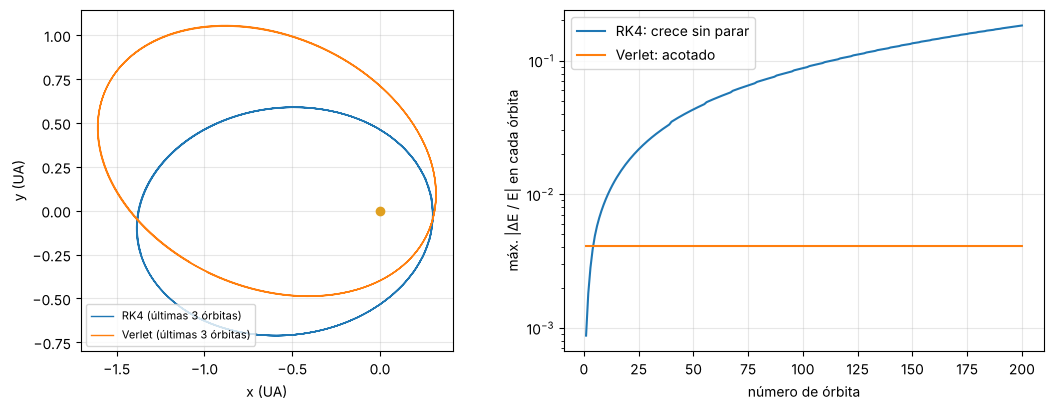

In [2]:
GM = 4*np.pi**2
e, a = 0.7, 1.0
r0 = np.array([a*(1 - e), 0.0])
v0 = np.array([0.0, np.sqrt(GM*(1 + e)/(a*(1 - e)))])    # rapidez en el perihelio
acc = lambda r: -GM*r/np.linalg.norm(r)**3
energia = lambda r, v: 0.5*v@v - GM/np.linalg.norm(r)
E0, ORBITAS = energia(r0, v0), 200

def rk4(dt):
    r, v = r0.copy(), v0.copy(); n = int(round(ORBITAS/dt)); dE = np.empty(n); xs = []
    for i in range(n):
        k1r, k1v = v, acc(r)
        k2r, k2v = v + dt/2*k1v, acc(r + dt/2*k1r)
        k3r, k3v = v + dt/2*k2v, acc(r + dt/2*k2r)
        k4r, k4v = v + dt*k3v, acc(r + dt*k3r)
        r = r + dt/6*(k1r + 2*k2r + 2*k3r + k4r); v = v + dt/6*(k1v + 2*k2v + 2*k3v + k4v)
        dE[i] = (energia(r, v) - E0)/abs(E0); xs.append(r)
    return dE, np.array(xs)

def verlet(dt):
    r, v = r0.copy(), v0.copy(); n = int(round(ORBITAS/dt)); dE = np.empty(n); xs = []; ac = acc(r)
    for i in range(n):
        v = v + dt/2*ac; r = r + dt*v; ac = acc(r); v = v + dt/2*ac
        dE[i] = (energia(r, v) - E0)/abs(E0); xs.append(r)
    return dE, np.array(xs)

dt = 0.008
dE_rk, x_rk = rk4(dt)
dE_vv, x_vv = verlet(dt/4)
n_rk, n_vv = int(1/dt), int(4/dt)              # pasos por órbita
rk_ini, rk_fin = np.abs(dE_rk[:10*n_rk]).max(), np.abs(dE_rk[-10*n_rk:]).max()
vv_ini, vv_fin = np.abs(dE_vv[:10*n_vv]).max(), np.abs(dE_vv[-10*n_vv:]).max()
print(f"RK4    : |ΔE/E| máx. órbitas 1–10 = {rk_ini:.2e} → órbitas 191–200 = {rk_fin:.2e}")
print(f"Verlet : |ΔE/E| máx. órbitas 1–10 = {vv_ini:.2e} → órbitas 191–200 = {vv_fin:.2e}")
verificar(vv_fin < 1.05*vv_ini, "Verlet: el error de energía no crece (acotado)")
verificar(rk_fin > 5*rk_ini, "RK4: el error de energía crece con el tiempo (deriva secular)")

# Tercera ley de Kepler con un integrador de alta precisión (DOP853, tolerancia 1e-12)
def f_kep(t, s):
    r = s[:2]; return [*s[2:], *acc(r)]
perihelio = lambda t, s: s[1]
perihelio.direction = 1
sol = solve_ivp(f_kep, (0, 3.5), [*r0, *v0], events=perihelio, method="DOP853", rtol=1e-12, atol=1e-12)
T_ref = np.diff(sol.t_events[0]).mean()
verificar(abs(T_ref - a**1.5) < 1e-6, f"Tercera ley: período {T_ref:.7f} años = a^(3/2) = {a**1.5:.7f} años")

# El período de Verlet sale algo más largo: su energía media está desplazada, y con ella el semieje
y = x_vv[:, 1]; cruces = np.where((y[:-1] < 0) & (y[1:] >= 0))[0]
T_vv = np.diff(cruces).mean()*dt/4
E_media = E0*(1 + np.mean(dE_vv)*np.sign(E0))
a_eff = -GM/(2*E_media)
print(f"Verlet: período {T_vv:.5f} años ({(T_vv - 1)*100:+.2f} %); semieje efectivo por su energía media = {a_eff:.5f} UA")
verificar(abs(T_vv - a_eff**1.5)/T_vv < 1e-3, "el período de Verlet cumple la tercera ley con su propia energía media")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2))
ax1.plot(x_rk[-3*n_rk:, 0], x_rk[-3*n_rk:, 1], lw=1, label="RK4 (últimas 3 órbitas)")
ax1.plot(x_vv[-3*n_vv:, 0], x_vv[-3*n_vv:, 1], lw=1, label="Verlet (últimas 3 órbitas)")
ax1.plot(0, 0, "o", color="#e0a020"); ax1.set_aspect("equal"); ax1.set_xlabel("x (UA)"); ax1.set_ylabel("y (UA)"); ax1.legend(fontsize=8, loc="lower left")
orb = np.arange(1, ORBITAS + 1)
ax2.semilogy(orb, np.abs(dE_rk).reshape(ORBITAS, n_rk).max(axis=1), label="RK4: crece sin parar")
ax2.semilogy(orb, np.abs(dE_vv).reshape(ORBITAS, n_vv).max(axis=1), label="Verlet: acotado")
ax2.set_xlabel("número de órbita"); ax2.set_ylabel("máx. |ΔE / E| en cada órbita"); ax2.legend(); plt.tight_layout(); plt.show()

**Lo que muestra la gráfica de la izquierda:** la órbita de RK4 se encogió (perdió energía), y la de Verlet conserva su forma, pero gira lentamente. Ese giro es una **precesión numérica**: un error de fase que Verlet acumula aunque su energía no derive. Ningún método es perfecto. Por eso cada resultado se contrasta con una ley física.

**Pregunta para el aula:** si RK4 es «más preciso» (orden 4), ¿por qué pierde frente a Verlet en simulaciones largas? ¿Qué método usaría para simular el Sistema Solar durante un millón de años?

**Prompt para variar con IA:** «Agrega un tercer integrador, Euler explícito, con el mismo costo, y muestra cómo la órbita se abre en espiral.»

## 2 · Péndulo doble: caos determinista

Dos péndulos acoplados con masas $m_1, m_2$ y longitudes $\ell_1, \ell_2$. Las ecuaciones de movimiento salen del lagrangiano. El control de la **energía** es la forma práctica de detectar un error de signo en ellas:

$$E = \tfrac12(m_1+m_2)\ell_1^2\dot\theta_1^2 + \tfrac12 m_2\ell_2^2\dot\theta_2^2 + m_2\ell_1\ell_2\dot\theta_1\dot\theta_2\cos(\theta_1-\theta_2) - (m_1+m_2)g\ell_1\cos\theta_1 - m_2 g\ell_2\cos\theta_2$$

Se lanzan dos péndulos que difieren en **una milmillonésima de radián** ($10^{-9}$).

✔ energía conservada durante 30 s (|ΔE/E| máx. = 3.3e-09)
La separación crece como e^(λt) con λ ≈ 0.97 s⁻¹ (estimación gruesa del exponente de Lyapunov)
Una diferencia inicial de 1e-9 rad supera 0,1 rad a los 19.0 s


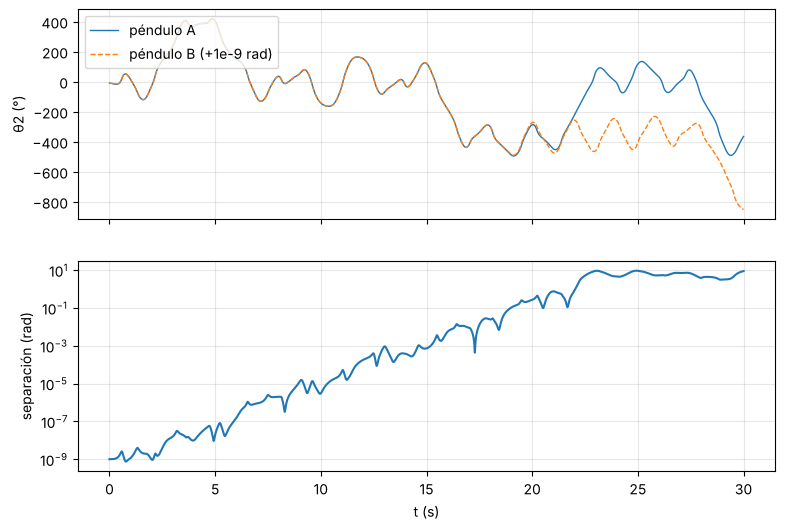

In [3]:
m1 = m2 = 1.0; l1 = l2 = 1.0; g = 9.81

def deriv(t, s):
    th1, w1, th2, w2 = s
    d = th2 - th1
    den1 = (m1 + m2)*l1 - m2*l1*np.cos(d)**2
    a1 = (m2*l1*w1**2*np.sin(d)*np.cos(d) + m2*g*np.sin(th2)*np.cos(d)
          + m2*l2*w2**2*np.sin(d) - (m1 + m2)*g*np.sin(th1))/den1
    den2 = (l2/l1)*den1
    a2 = (-m2*l2*w2**2*np.sin(d)*np.cos(d)
          + (m1 + m2)*(g*np.sin(th1)*np.cos(d) - l1*w1**2*np.sin(d) - g*np.sin(th2)))/den2
    return [w1, a1, w2, a2]

def energia(s):
    th1, w1, th2, w2 = s
    return (0.5*(m1 + m2)*l1**2*w1**2 + 0.5*m2*l2**2*w2**2 + m2*l1*l2*w1*w2*np.cos(th1 - th2)
            - (m1 + m2)*g*l1*np.cos(th1) - m2*g*l2*np.cos(th2))

t = np.linspace(0, 30, 6001)
s0 = np.array([np.radians(120), 0, np.radians(-10), 0])
A = solve_ivp(deriv, (0, 30), s0, t_eval=t, method="DOP853", rtol=1e-12, atol=1e-12)
B = solve_ivp(deriv, (0, 30), s0 + [1e-9, 0, 0, 0], t_eval=t, method="DOP853", rtol=1e-12, atol=1e-12)

E = energia(A.y); dE = np.max(np.abs(E - E[0]))/abs(E[0])
verificar(dE < 1e-8, f"energía conservada durante 30 s (|ΔE/E| máx. = {dE:.1e})")

sep = np.hypot(A.y[0] - B.y[0], A.y[2] - B.y[2])
crece = (sep > 1e-8) & (sep < 1e-2)
lam = np.polyfit(t[crece], np.log(sep[crece]), 1)[0]
t_div = t[np.argmax(sep > 0.1)]
print(f"La separación crece como e^(λt) con λ ≈ {lam:.2f} s⁻¹ (estimación gruesa del exponente de Lyapunov)")
print(f"Una diferencia inicial de 1e-9 rad supera 0,1 rad a los {t_div:.1f} s")

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax1.plot(t, np.degrees(A.y[2]), lw=1, label="péndulo A"); ax1.plot(t, np.degrees(B.y[2]), lw=1, ls="--", label="péndulo B (+1e-9 rad)")
ax1.set_ylabel("θ2 (°)"); ax1.legend(loc="upper left")
ax2.semilogy(t, sep); ax2.set_xlabel("t (s)"); ax2.set_ylabel("separación (rad)"); plt.show()

**Pregunta para el aula:** el sistema es completamente determinista. ¿Por qué entonces no se puede predecir su estado a los 30 s? ¿Qué relación tiene esto con el pronóstico del tiempo?

**Prompt para variar con IA:** «Cambia la amplitud inicial a 10° y muestra que, para ángulos pequeños, la separación ya no crece exponencialmente.»

## 3 · Ecuación del calor: una línea de código separa lo correcto del absurdo

$$\frac{\partial u}{\partial t} = \alpha\,\frac{\partial^2 u}{\partial x^2},\qquad u(0,t) = u(L,t) = 0,\qquad u(x,0) = \text{triángulo de altura } L/2$$

Método explícito (FTCS): $u_i^{n+1} = u_i^n + r\,(u_{i+1}^n - 2u_i^n + u_{i-1}^n)$, con $r = \alpha\,\Delta t/\Delta x^2$. Es estable solo si $r \le \tfrac12$.

Solución exacta por serie de Fourier: $u(x,t) = \sum_n b_n\, e^{-\alpha n^2\pi^2 t/L^2}\sin\frac{n\pi x}{L}$ con $b_n = \dfrac{4L}{n^2\pi^2}\sin\dfrac{n\pi}{2}$.

✔ la serie de Fourier reproduce la condición inicial
✔ r = 0.4 (estable): FTCS coincide con la solución exacta
✔ r = 0.52 (inestable): FTCS diverge, error 2.7e+04 con un 4 % más de paso


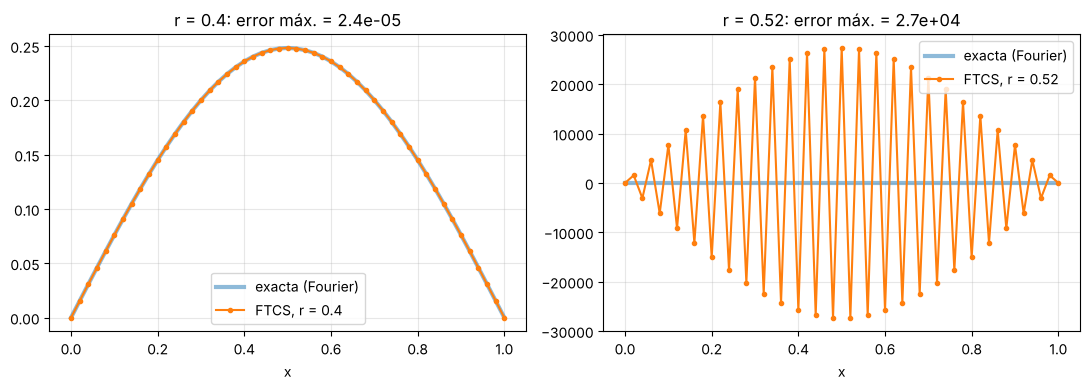

In [4]:
L, alpha, Nx, t_fin = 1.0, 1.0, 51, 0.05
x = np.linspace(0, L, Nx); dx = x[1] - x[0]
u0 = np.where(x < L/2, x, L - x)

def exacta(t, N=400):
    n = np.arange(1, N + 1)[:, None]
    bn = 4*L/(n**2*np.pi**2)*np.sin(n*np.pi/2)
    return np.sum(bn*np.exp(-alpha*n**2*np.pi**2*t/L**2)*np.sin(n*np.pi*x/L), axis=0)

verificar(np.max(np.abs(exacta(0) - u0)) < 2e-3, "la serie de Fourier reproduce la condición inicial")

def ftcs(r):
    dt = r*dx**2/alpha; n = int(round(t_fin/dt)); u = u0.copy()
    for _ in range(n):
        u[1:-1] = u[1:-1] + r*(u[2:] - 2*u[1:-1] + u[:-2])
    return u, n*dt

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for r, ax in zip((0.40, 0.52), axs):
    u, t = ftcs(r)
    err = np.max(np.abs(u - exacta(t)))
    ax.plot(x, exacta(t), lw=3, alpha=.5, label="exacta (Fourier)"); ax.plot(x, u, "o-", ms=3, label=f"FTCS, r = {r}")
    ax.set_title(f"r = {r}: error máx. = {err:.1e}"); ax.set_xlabel("x"); ax.legend()
    if r <= 0.5:
        verificar(err < 2e-3, f"r = {r} (estable): FTCS coincide con la solución exacta")
    else:
        verificar(err > 1.0, f"r = {r} (inestable): FTCS diverge, error {err:.1e} con un 4 % más de paso")
plt.tight_layout(); plt.show()

**Pregunta para el aula:** pasar de $r = 0{,}50$ a $r = 0{,}52$ es un cambio de 4 % en el paso de tiempo. ¿Por qué el resultado pasa de correcto a absurdo? ¿Qué modo de Fourier crece primero?

**Prompt para variar con IA:** «Implementa el método de Crank–Nicolson para el mismo problema y verifica que es estable con r = 5.»

## 4 · Oscilador armónico cuántico por diferencias finitas

Unidades $\hbar = m = \omega = 1$: $\;\hat H = -\tfrac12\dfrac{d^2}{dx^2} + \tfrac12 x^2 + \lambda x^4$.

Discretizar la segunda derivada convierte $\hat H$ en una matriz tridiagonal; sus autovalores aproximan las energías.

- Con $\lambda = 0$ la respuesta exacta es $E_n = n + \tfrac12$.
- Con $\lambda$ pequeño, la teoría de perturbaciones a primer orden da $E_0 \approx \tfrac12 + \lambda\langle x^4\rangle_0 = \tfrac12 + \tfrac34\lambda$.
- Con $\lambda$ grande, la perturbación falla y solo queda el cálculo numérico.

✔ λ = 0: E_n = n + ½ para n = 0…5 (error relativo máx. 8.7e-06)
✔ λ = 0.001: E0 = 0.5007466 ≈ ½ + ¾λ = 0.5007500 (primer orden)
λ = 0.01 : numérico E0 = 0.50726   primer orden = 0.50750   diferencia = 0.05 %
λ = 0.1  : numérico E0 = 0.55915   primer orden = 0.57500   diferencia = 2.84 %
λ = 1.0  : numérico E0 = 0.80377   primer orden = 1.25000   diferencia = 55.52 %


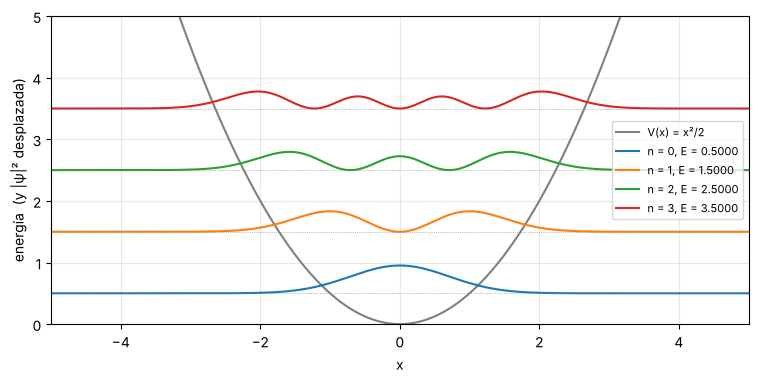

In [5]:
Lx, N = 10.0, 4000
x = np.linspace(-Lx, Lx, N); h = x[1] - x[0]

def niveles(lam, k=6):
    diag = 1/h**2 + 0.5*x**2 + lam*x**4
    off = -0.5/h**2*np.ones(N - 1)
    return eigh_tridiagonal(diag, off, select="i", select_range=(0, k - 1))

E, psi = niveles(0.0)
err = np.max(np.abs(E - (np.arange(6) + 0.5))/(np.arange(6) + 0.5))
verificar(err < 1e-5, f"λ = 0: E_n = n + ½ para n = 0…5 (error relativo máx. {err:.1e})")

lam = 0.001
E0 = niveles(lam, 1)[0][0]
verificar(abs(E0 - (0.5 + 0.75*lam)) < 5e-6, f"λ = {lam}: E0 = {E0:.7f} ≈ ½ + ¾λ = {0.5 + 0.75*lam:.7f} (primer orden)")
for lam in (0.01, 0.1, 1.0):
    E0 = niveles(lam, 1)[0][0]
    print(f"λ = {lam:<5}: numérico E0 = {E0:.5f}   primer orden = {0.5 + 0.75*lam:.5f}   diferencia = {abs(E0 - 0.5 - 0.75*lam)/E0*100:.2f} %")

E, psi = niveles(0.0)
plt.plot(x, 0.5*x**2, color="gray", label="V(x) = x²/2")
for n in range(4):
    p = psi[:, n]/np.sqrt(h)
    plt.plot(x, E[n] + 0.8*p**2, label=f"n = {n}, E = {E[n]:.4f}"); plt.axhline(E[n], color="gray", lw=.5, ls=":")
plt.xlim(-5, 5); plt.ylim(0, 5); plt.xlabel("x"); plt.ylabel("energía  (y |ψ|² desplazada)"); plt.legend(fontsize=8); plt.show()

**Pregunta para el aula:** ¿por qué la densidad de probabilidad clásica de un oscilador es mayor en los extremos, y qué le pasa a $|\psi_n|^2$ cuando $n$ crece?

**Prompt para variar con IA:** «Usa el mismo método para un pozo finito de profundidad V0 y verifica el número de estados ligados contra la condición de la ecuación trascendente.»

## 5 · Incertidumbre por Monte Carlo (GUM, Suplemento 1)

Medición de $g = 4\pi^2 L/T^2$ con un péndulo. La GUM propaga incertidumbres **linealizando**:

$$\frac{u(g)}{g} = \sqrt{\left(\frac{u(L)}{L}\right)^2 + \left(2\,\frac{u(T)}{T}\right)^2}$$

El Suplemento 1 de la GUM (JCGM 101:2008) propaga **distribuciones completas** por Monte Carlo. Si las incertidumbres son pequeñas, ambos métodos coinciden. Si son grandes, la linealización falla: la distribución de $g$ se vuelve asimétrica.

u(T) = 2 ms  : GUM lineal g = 9.773 ± 0.028 | Monte Carlo media 9.773, desv. 0.028, intervalo 95 % [9.719, 9.827]
✔ incertidumbre pequeña: Monte Carlo y GUM lineal coinciden (< 1 %)
u(T) = 150 ms: GUM lineal g = 9.773 ± 1.459 | Monte Carlo media 9.940, desv. 1.531, intervalo 95 % [7.438, 13.410]
✔ incertidumbre grande: la distribución es asimétrica (cola superior 1.56 veces la inferior); la GUM lineal ya no basta


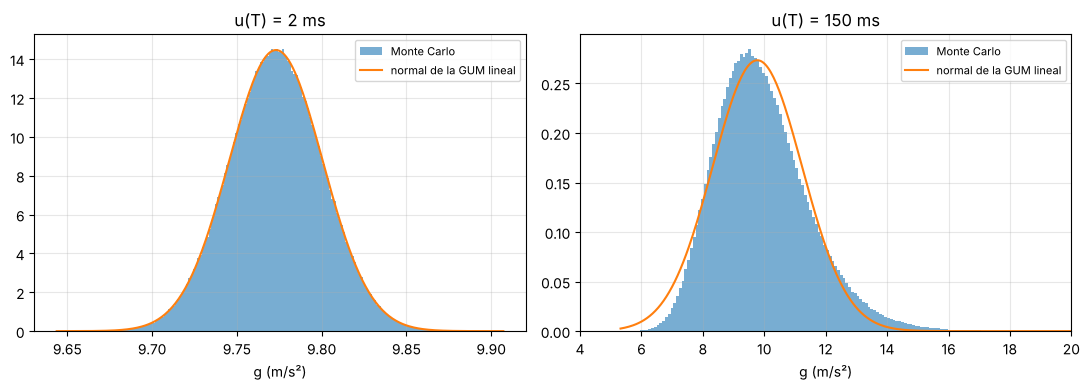

In [6]:
rng = np.random.default_rng(2026)
M = 1_000_000
L, uL = 1.000, 0.002                  # m: longitud y su incertidumbre estándar
T = 2*np.pi*np.sqrt(L/9.773)          # s, período esperado en La Paz

def comparar(uT, etiqueta):
    g_lin = 4*np.pi**2*L/T**2
    u_lin = g_lin*np.sqrt((uL/L)**2 + (2*uT/T)**2)
    Ls = rng.normal(L, uL, M); Ts = rng.normal(T, uT, M)
    gs = 4*np.pi**2*Ls/Ts**2
    lo, hi = np.percentile(gs, [2.5, 97.5])
    print(f"{etiqueta}: GUM lineal g = {g_lin:.3f} ± {u_lin:.3f} | Monte Carlo media {gs.mean():.3f}, "
          f"desv. {gs.std():.3f}, intervalo 95 % [{lo:.3f}, {hi:.3f}]")
    return g_lin, u_lin, gs

g1, u1, gs1 = comparar(0.002, "u(T) = 2 ms  ")
verificar(abs(gs1.std() - u1)/u1 < 0.01, "incertidumbre pequeña: Monte Carlo y GUM lineal coinciden (< 1 %)")
g2, u2, gs2 = comparar(0.15, "u(T) = 150 ms")
asim = (np.percentile(gs2, 97.5) - g2) / (g2 - np.percentile(gs2, 2.5))
verificar(asim > 1.2, f"incertidumbre grande: la distribución es asimétrica (cola superior {asim:.2f} veces la inferior); la GUM lineal ya no basta")

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, gs, g0, u, tit in ((axs[0], gs1, g1, u1, "u(T) = 2 ms"), (axs[1], gs2, g2, u2, "u(T) = 150 ms")):
    ax.hist(gs, bins=200, density=True, alpha=.6, label="Monte Carlo")
    xx = np.linspace(gs.min(), gs.max(), 400)
    ax.plot(xx, np.exp(-0.5*((xx - g0)/u)**2)/(u*np.sqrt(2*np.pi)), label="normal de la GUM lineal")
    ax.set_title(tit); ax.set_xlabel("g (m/s²)"); ax.legend(fontsize=8)
axs[1].set_xlim(4, 20); plt.tight_layout(); plt.show()

**Pregunta para el aula:** con un cronómetro de mano (tiempo de reacción ≈ 0,15 s), ¿conviene medir una oscilación o veinte? Cuantifíquelo con esta misma celda.

**Prompt para variar con IA:** «Modela el tiempo de reacción como una distribución uniforme en lugar de normal y compara los intervalos de 95 %.»

---
*Material del Módulo 8, «El auxiliar aumentado». Licencia CC BY 4.0. Referencia: JCGM 101:2008, Evaluation of measurement data — Supplement 1 to the GUM — Propagation of distributions using a Monte Carlo method, doi:10.59161/JCGM101-2008.*